--- 开始分析平均距离 (为小提琴图准备数据) ---

处理组: V410-F808, 条件: US
  -> 文件: V410-F808_1.xvg      | 平均距离: 0.6631
  -> 文件: V410-F808_2.xvg      | 平均距离: 0.8509
  -> 文件: V410-F808_3.xvg      | 平均距离: 0.5909
  -> 统计结果: 平均值 = 0.7017, S.E.M = 0.0775

处理组: V410-F808, 条件: BS
  -> 文件: V410-F808_1.xvg      | 平均距离: 0.6803
  -> 文件: V410-F808_2.xvg      | 平均距离: 0.7129
  -> 文件: V410-F808_3.xvg      | 平均距离: 0.6177
  -> 统计结果: 平均值 = 0.6703, S.E.M = 0.0279

处理组: R411-F808, 条件: US
  -> 文件: R411-F808_1.xvg      | 平均距离: 1.3450
  -> 文件: R411-F808_2.xvg      | 平均距离: 1.1821
  -> 文件: R411-F808_3.xvg      | 平均距离: 1.0798
  -> 统计结果: 平均值 = 1.2023, S.E.M = 0.0772

处理组: R411-F808, 条件: BS
  -> 文件: R411-F808_1.xvg      | 平均距离: 1.2100
  -> 文件: R411-F808_2.xvg      | 平均距离: 1.2077
  -> 文件: R411-F808_3.xvg      | 平均距离: 1.2647
  -> 统计结果: 平均值 = 1.2275, S.E.M = 0.0186

--- 分析完成，开始绘制小提琴图 ---

--- 绘图完成，已保存为 average_distance_violin_comparison.png ---


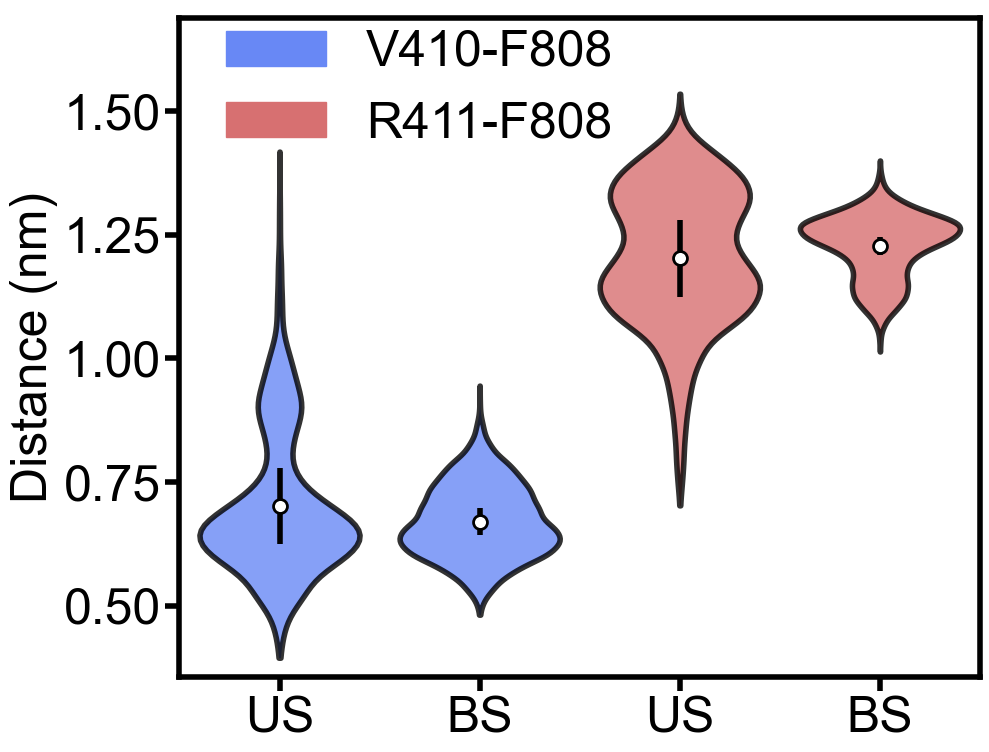

In [54]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1. 核心配置区域 (这是您唯一需要修改的地方) ---
analysis_config = [
    {
        "group_name": "V410-F808",  # 用于图例的名称
        "color": "#6888F5",       # 小提琴的颜色
        "conditions": [           # 该组下的不同条件
            {
                "label": "US",    # X轴上显示的标签
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro+1protonating/analysis/dis-lflip',
                "prefix": 'V410-F808', # 文件前缀
            },
            {
                "label": "BS",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro_DNA+1protonating/analysis/dis-lflip',
                "prefix": 'V410-F808',
            }
        ]
    },
    {
        "group_name": "R411-F808",
        "color": "#D77071",
        "conditions": [
            {
                "label": "US",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro+1protonating/analysis/dis-lflip',
                "prefix": 'R411-F808', # <--- 请确保前缀与您的文件名匹配
            },
            {
                "label": "BS",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro_DNA+1protonating/analysis/dis-lflip',
                "prefix": 'R411-F808', # <--- 请确保前缀与您的文件名匹配
            }
        ]
    },
    # --- 您可以在这里添加更多组 ---
]

# --- 全局分析参数 ---
analysis_params = {
    "start_frame": 8000,
    "end_frame": None, # 设置为None则分析到末尾
    "replicates": ["_1.xvg", "_2.xvg", "_3.xvg"]
}

# --- 2. 数据处理与统计 (为小提琴图进行修改) ---

plot_data = {
    "violin_data": [], # 存储每个violin的完整数据
    "means": [],
    "sems": [],
    "x_labels": [],
    "violin_colors": []
}

print("--- 开始分析平均距离 (为小提琴图准备数据) ---")
for group in analysis_config:
    for condition in group['conditions']:
        replicate_avg_distances = []
        all_distances_for_condition = [] # 新增: 存储此条件下的所有数据点
        
        print(f"\n处理组: {group['group_name']}, 条件: {condition['label']}")
        
        for rep_suffix in analysis_params["replicates"]:
            file_pattern = f"{condition['prefix']}{rep_suffix}"
            file_path = os.path.join(condition['folder'], file_pattern)
            
            if not os.path.exists(file_path):
                print(f"  -> 未找到文件: {file_path}")
                continue
            
            single_file_distances = []
            frame_index = 0
            try:
                with open(file_path, 'r') as f:
                    for line in f:
                        if line.strip().startswith(('#', '@')):
                            continue
                        if analysis_params["end_frame"] is not None and frame_index >= analysis_params["end_frame"]:
                            break
                        if frame_index >= analysis_params["start_frame"]:
                            columns = line.split()
                            if len(columns) >= 2:
                                single_file_distances.append(float(columns[1]))
                        frame_index += 1
                
                if single_file_distances:
                    avg_dist_for_rep = np.mean(single_file_distances)
                    replicate_avg_distances.append(avg_dist_for_rep)
                    all_distances_for_condition.extend(single_file_distances) # 将数据点添加到总列表
                    print(f"  -> 文件: {file_pattern:<20} | 平均距离: {avg_dist_for_rep:.4f}")
                else:
                    print(f"  -> 文件: {file_pattern} 在指定帧数范围内无数据。")

            except Exception as e:
                print(f"    读取或处理文件 {file_path} 时出错: {e}")
        
        if replicate_avg_distances:
            mean_of_reps = np.mean(replicate_avg_distances)
            sem_of_reps = 0
            if len(replicate_avg_distances) > 1:
                sem_of_reps = np.std(replicate_avg_distances, ddof=1) / np.sqrt(len(replicate_avg_distances))

            plot_data["violin_data"].append(all_distances_for_condition)
            plot_data["means"].append(mean_of_reps)
            plot_data["sems"].append(sem_of_reps)
            plot_data["x_labels"].append(condition['label'])
            plot_data["violin_colors"].append(group['color'])
            print(f"  -> 统计结果: 平均值 = {mean_of_reps:.4f}, S.E.M = {sem_of_reps:.4f}")

print("\n--- 分析完成，开始绘制小提琴图 ---")

# --- 3. 绘图部分 (修改为Violin Plot) ---

plt.rcParams.update({
    'font.family': 'Arial', 'axes.titlesize': 36, 'axes.labelsize': 36,
    'xtick.labelsize': 36, 'ytick.labelsize': 36, 'legend.fontsize': 36,
    'figure.figsize': (10, 8), 'axes.linewidth': 4, 'axes.edgecolor': 'black',
    'xtick.color': 'black', 'ytick.color': 'black', 'xtick.major.size': 10,
    'ytick.major.size': 10, 'xtick.major.width': 4, 'ytick.major.width': 4,
    'axes.grid': False,
})

fig, ax = plt.subplots()
x = np.arange(1, len(plot_data["means"]) + 1)

# 绘制小提琴图
violins = ax.violinplot(plot_data["violin_data"], positions=x,
                        showmeans=False, showmedians=False, showextrema=False, widths=0.8)

# 自定义小提琴的颜色和样式
for i, pc in enumerate(violins['bodies']):
    pc.set_facecolor(plot_data["violin_colors"][i])
    pc.set_edgecolor('black')
    pc.set_linewidth(4)
    pc.set_alpha(0.8)

# 在小提琴内部绘制均值点和SEM误差线
means = np.array(plot_data["means"])
sems = np.array(plot_data["sems"])
ax.scatter(x, means, marker='o', color='white', s=100, zorder=3, edgecolors='black', linewidth=2)
ax.vlines(x, means - sems, means + sems, color='black', linestyle='-', lw=4, zorder=2)


# 设置Y轴标签和范围
ax.set_ylabel('Distance (nm)')
# 动态调整Y轴范围以更好地显示数据分布
all_data_flat = [item for sublist in plot_data["violin_data"] for item in sublist]
if all_data_flat:
    min_val = min(all_data_flat)
    max_val = max(all_data_flat)
    ax.set_ylim(min_val * 0.9, max_val * 1.1)

# 设置X轴刻度和标签
ax.set_xticks(x)
ax.set_xticklabels(plot_data["x_labels"])
ax.set_xlim(0.5, len(x) + 0.5)

# 创建并添加图例
legend_patches = [mpatches.Patch(color=group["color"], label=group["group_name"]) for group in analysis_config]
ax.legend(frameon=False, handles=legend_patches, loc='upper center', bbox_to_anchor=(0.3, 1.05), ncol=1)

# 调整布局以防止标签重叠
plt.tight_layout(rect=[0, 0, 1, 0.95])

# 保存图像
output_filename = 'average_distance_violin_comparison.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
print(f"\n--- 绘图完成，已保存为 {output_filename} ---")
plt.show()

--- 开始分析接触概率 (基于接触数) ---

处理组: V410-F808, 条件: US
  -> 文件: contact_numbers_V410-F808_1.xvg | 接触概率: 0.9960
  -> 文件: contact_numbers_V410-F808_2.xvg | 接触概率: 0.3818
  -> 文件: contact_numbers_V410-F808_3.xvg | 接触概率: 0.9670
  -> 统计结果: 平均概率 = 0.7816, S.E.M = 0.2001

处理组: V410-F808, 条件: BS
  -> 文件: contact_numbers_V410-F808_1.xvg | 接触概率: 0.9895
  -> 文件: contact_numbers_V410-F808_2.xvg | 接触概率: 0.9340
  -> 文件: contact_numbers_V410-F808_3.xvg | 接触概率: 1.0000
  -> 统计结果: 平均概率 = 0.9745, S.E.M = 0.0205

处理组: R411-F808, 条件: US
  -> 文件: contact_numbers_R411-F808_1.xvg | 接触概率: 0.0000
  -> 文件: contact_numbers_R411-F808_2.xvg | 接触概率: 0.0000
  -> 文件: contact_numbers_R411-F808_3.xvg | 接触概率: 0.0510
  -> 统计结果: 平均概率 = 0.0170, S.E.M = 0.0170

处理组: R411-F808, 条件: BS
  -> 文件: contact_numbers_R411-F808_1.xvg | 接触概率: 0.0000
  -> 文件: contact_numbers_R411-F808_2.xvg | 接触概率: 0.0000
  -> 文件: contact_numbers_R411-F808_3.xvg | 接触概率: 0.0000
  -> 统计结果: 平均概率 = 0.0000, S.E.M = 0.0000

--- 分析完成，开始绘图 ---

--- 绘图完成，已保存为 contact_p

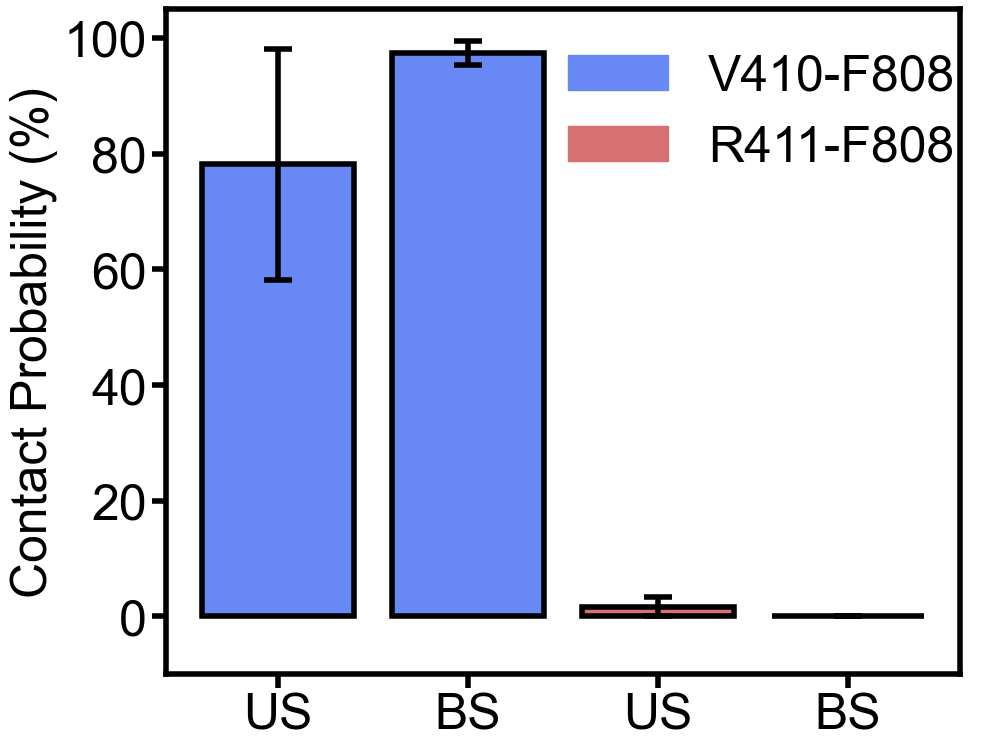

In [50]:
import os
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- 1. 接触判断函数 (已更新) ---
def check_contact_exists(contact_count):
    """
    根据接触数量判断接触是否存在。
    
    参数:
    contact_count (int): 当前帧的原子对接触数量。
    
    返回:
    float: 如果接触数 >= 1, 则为 1.0, 否则为 0.0。
    """
    return 1.0 if contact_count >= 1 else 0.0

# --- 2. 核心配置区域 (与您提供的代码一致) ---
analysis_config = [
    {
        "group_name": "V410-F808",
        "color": "#6888F5",
        "conditions": [
            {
                "label": "US",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro+1protonating/analysis/dis-lflip',
                "prefix": 'contact_numbers_V410-F808',
            },
            {
                "label": "BS",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro_DNA+1protonating/analysis/dis-lflip',
                "prefix": 'contact_numbers_V410-F808',
            }
        ]
    },
    {
        "group_name": "R411-F808",
        "color": "#D77071",
        "conditions": [
            {
                "label": "US",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro+1protonating/analysis/dis-lflip',
                "prefix": 'contact_numbers_R411-F808',
            },
            {
                "label": "BS",
                "folder": '/data/jychen/MD_projects/SMC/All_Atoms/normalMD/Fullpro_DNA+1protonating/analysis/dis-lflip',
                "prefix": 'contact_numbers_R411-F808',
            }
        ]
    },
]

# --- 全局分析参数 (已更新) ---
# 不再需要cutoff, 因为判断是基于接触数是否>0
analysis_params = {
    "start_frame": 8000,
    "end_frame": None,
    "replicates": ["_1.xvg", "_2.xvg", "_3.xvg"]
}

# --- 3. 数据处理与统计 (逻辑已更新) ---

plot_data = {
    "means": [],
    "sems": [],
    "x_labels": [],
    "bar_colors": []
}

print("--- 开始分析接触概率 (基于接触数) ---")
for group in analysis_config:
    for condition in group['conditions']:
        replicate_probabilities = []
        print(f"\n处理组: {group['group_name']}, 条件: {condition['label']}")
        
        for rep_suffix in analysis_params["replicates"]:
            file_pattern = f"{condition['prefix']}{rep_suffix}"
            file_path = os.path.join(condition['folder'], file_pattern)
            
            if not os.path.exists(file_path):
                print(f"  -> 未找到文件: {file_path}")
                continue
            
            # --- 读取文件并计算单个文件的接触概率 ---
            contact_frames = 0
            frames_analyzed = 0
            frame_index = 0
            try:
                with open(file_path, 'r') as f:
                    for line in f:
                        if line.strip().startswith(('#', '@')):
                            continue
                        if analysis_params["end_frame"] is not None and frame_index >= analysis_params["end_frame"]:
                            break
                        if frame_index >= analysis_params["start_frame"]:
                            frames_analyzed += 1
                            columns = line.split()
                            if len(columns) >= 2:
                                # **核心改动 1**: 读取的值是“接触数”，而不是“距离”
                                contact_count = int(float(columns[1]))
                                
                                # **核心改动 2**: 调用新的判断函数
                                contact_value = check_contact_exists(contact_count)
                                contact_frames += contact_value # 接触则+1, 否则+0
                        frame_index += 1
                
                if frames_analyzed > 0:
                    probability_for_rep = contact_frames / frames_analyzed
                    replicate_probabilities.append(probability_for_rep)
                    print(f"  -> 文件: {file_pattern:<20} | 接触概率: {probability_for_rep:.4f}")
                else:
                    print(f"  -> 文件: {file_pattern} 在指定帧数范围内无数据。")

            except Exception as e:
                print(f"    读取或处理文件 {file_path} 时出错: {e}")
        
        # --- 对该条件下的所有重复模拟结果进行统计 ---
        if len(replicate_probabilities) > 0:
            mean_of_reps = np.mean(replicate_probabilities)
            
            sem_of_reps = 0
            if len(replicate_probabilities) > 1:
                sem_of_reps = np.std(replicate_probabilities, ddof=1) / np.sqrt(len(replicate_probabilities))

            # 将结果（0到1之间）存入绘图数据字典
            plot_data["means"].append(mean_of_reps)
            plot_data["sems"].append(sem_of_reps)
            plot_data["x_labels"].append(condition['label'])
            plot_data["bar_colors"].append(group['color'])
            print(f"  -> 统计结果: 平均概率 = {mean_of_reps:.4f}, S.E.M = {sem_of_reps:.4f}")

print("\n--- 分析完成，开始绘图 ---")

# --- 4. 绘图部分 (基本无需修改) ---

plt.rcParams.update({
    'font.family': 'Arial', 'axes.titlesize': 36, 'axes.labelsize': 36,
    'xtick.labelsize': 36, 'ytick.labelsize': 36, 'legend.fontsize': 36,
    'figure.figsize': (10, 8), 'axes.linewidth': 4, 'axes.edgecolor': 'black',
    'xtick.color': 'black', 'ytick.color': 'black', 'xtick.major.size': 10,
    'ytick.major.size': 10, 'xtick.major.width': 4, 'ytick.major.width': 4,
    'axes.grid': False,
})

fig, ax = plt.subplots()
x = np.arange(len(plot_data["means"]))

# 将概率转换为百分比进行绘图
means_percent = [p * 100 for p in plot_data["means"]]
sems_percent = [s * 100 for s in plot_data["sems"]]

ax.bar(x, means_percent, yerr=sems_percent, 
       capsize=10, error_kw={'elinewidth': 4, 'capthick': 4}, 
       color=plot_data["bar_colors"], edgecolor='black', linewidth=4)

ax.set_ylabel('Contact Probability (%)')
ax.set_ylim(-10, 105) # 设置Y轴为0-100%

ax.set_xticks(x)
ax.set_xticklabels(plot_data["x_labels"])

legend_patches = [mpatches.Patch(color=group["color"], label=group["group_name"]) for group in analysis_config]
ax.legend(frameon=False, handles=legend_patches, loc='upper center', bbox_to_anchor=(0.75, 1.0), ncol=1)

plt.tight_layout(rect=[0, 0, 1, 0.95])

output_filename = 'contact_probability_from_counts.png'
plt.savefig(output_filename, dpi=300, bbox_inches='tight')
print(f"\n--- 绘图完成，已保存为 {output_filename} ---")
plt.show()